# Model Experimentations

This notebook compares the current linear classification models on the **same train/validation split and preprocessing pipeline**.

Main validation metrics:

- **F1 score**: balances precision and recall for the positive class.
- **Balanced accuracy**: average of recall and specificity, useful for the imbalanced `_MICHD` target.
- **Thresholds are tuned on the validation split**, so avoid repeatedly expanding the search purely to gain tiny validation improvements.

Current preprocessing and feature selection are handled by `src/preprocessing.py`.


## 1. Setup and data


In [33]:
from pathlib import Path
import sys
import numpy as np

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

from src.preprocessing import prepare_data, CALCULATED_FEATURES
from src.implementations import (
    logistic_regression,
    reg_logistic_regression,
    least_squares,
    ridge_regression,
)
from src.metrics import classification_metrics
from helpers import sigmoid

DATA_DIR = PROJECT_ROOT / "data" / "dataset"

(
    x_train_final,
    x_val_final,
    x_test_final,
    headers_final,
    y_train_split,
    y_val_split,
) = prepare_data(DATA_DIR)

y_train_log = (y_train_split == 1).astype(int)
y_val_log = (y_val_split == 1).astype(int)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Shared evaluation helpers

Logistic regression produces probabilities after the sigmoid. Ridge regression produces unrestricted continuous scores.

The same threshold-search helper can therefore be used for both as long as the appropriate score grid is supplied.


In [12]:
def evaluate_thresholds(y_true_01, scores, thresholds):
    best_f1 = -np.inf
    best_f1_threshold = None

    best_balanced = -np.inf
    best_balanced_threshold = None

    for threshold in thresholds:
        y_pred = (scores >= threshold).astype(int)
        metrics = classification_metrics(y_true_01, y_pred)

        if metrics["f1"] > best_f1:
            best_f1 = metrics["f1"]
            best_f1_threshold = threshold

        if metrics["balanced_accuracy"] > best_balanced:
            best_balanced = metrics["balanced_accuracy"]
            best_balanced_threshold = threshold

    return {
        "best_f1": best_f1,
        "f1_threshold": best_f1_threshold,
        "best_balanced_accuracy": best_balanced,
        "balanced_threshold": best_balanced_threshold,
    }


def print_results(results, parameter_name):
    for result in results:
        print(
            f"{parameter_name}={result[parameter_name]:.6g} | "
            f"loss={result['loss']:.6f} | "
            f"F1={result['best_f1']:.4f} "
            f"(t={result['f1_threshold']:.4f}) | "
            f"balanced acc={result['best_balanced_accuracy']:.4f} "
            f"(t={result['balanced_threshold']:.4f})"
        )


## 3. Plain logistic regression

Preliminary tuning found a stable region around `gamma = 1.0`.

The iteration sweep showed that performance had essentially plateaued by `1000` iterations, so the baseline uses:

- `gamma = 1.0`
- `max_iters = 1000`

The default probability threshold `0.5` is not appropriate for this strongly imbalanced target, so thresholds are evaluated separately.


In [13]:
LOGISTIC_GAMMA = 1.0
LOGISTIC_MAX_ITERS = 1000
LOGISTIC_THRESHOLDS = np.arange(0.02, 0.301, 0.01)

initial_w = np.zeros(x_train_final.shape[1])

w_logistic, loss_logistic = logistic_regression(
    y_train_log,
    x_train_final,
    initial_w,
    LOGISTIC_MAX_ITERS,
    LOGISTIC_GAMMA,
)

logistic_prob = sigmoid(x_val_final @ w_logistic)

logistic_eval = evaluate_thresholds(
    y_val_log,
    logistic_prob,
    LOGISTIC_THRESHOLDS,
)

logistic_result = {
    "model": "Logistic regression",
    "loss": loss_logistic,
    **logistic_eval,
}

print(logistic_result)


{'model': 'Logistic regression', 'loss': np.float64(0.23509497250538836), 'best_f1': np.float64(0.38997361477572556), 'f1_threshold': np.float64(0.18999999999999997), 'best_balanced_accuracy': np.float64(0.762143636925987), 'balanced_threshold': np.float64(0.09)}


### Current baseline

Previous tuning gave approximately:

- best F1: **0.390** at threshold **0.19**
- best balanced accuracy: **0.762** at threshold **0.09**

These thresholds optimize different objectives, so neither is universally the correct threshold.


## 4. Regularized logistic regression

Keep the logistic optimization settings fixed and vary only `lambda`.

`lambda = 1.0` is excluded because the combination with `gamma = 1.0` was numerically unstable in the current implementation. Performance was already deteriorating strongly by `lambda = 0.1`, so the smaller range is sufficient for this comparison.


In [14]:
REG_LOGISTIC_LAMBDAS = [
    0.0,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1,
]

reg_logistic_results = []
reg_logistic_models = {}

for lambda_ in REG_LOGISTIC_LAMBDAS:
    initial_w = np.zeros(x_train_final.shape[1])

    w, loss = reg_logistic_regression(
        y_train_log,
        x_train_final,
        lambda_,
        initial_w,
        LOGISTIC_MAX_ITERS,
        LOGISTIC_GAMMA,
    )

    if not np.isfinite(loss) or not np.all(np.isfinite(w)):
        print(f"Skipping unstable run: lambda={lambda_}")
        continue

    val_prob = sigmoid(x_val_final @ w)

    evaluation = evaluate_thresholds(
        y_val_log,
        val_prob,
        LOGISTIC_THRESHOLDS,
    )

    reg_logistic_models[lambda_] = w
    reg_logistic_results.append({
        "lambda": lambda_,
        "loss": loss,
        **evaluation,
    })

print_results(reg_logistic_results, "lambda")


lambda=0 | loss=0.235095 | F1=0.3900 (t=0.1900) | balanced acc=0.7621 (t=0.0900)
lambda=1e-05 | loss=0.235100 | F1=0.3905 (t=0.1800) | balanced acc=0.7622 (t=0.0900)
lambda=0.0001 | loss=0.235153 | F1=0.3910 (t=0.1800) | balanced acc=0.7624 (t=0.0900)
lambda=0.001 | loss=0.236302 | F1=0.3861 (t=0.1900) | balanced acc=0.7592 (t=0.0900)
lambda=0.01 | loss=0.248643 | F1=0.3589 (t=0.1800) | balanced acc=0.7450 (t=0.1000)
lambda=0.1 | loss=0.304767 | F1=0.2925 (t=0.2200) | balanced acc=0.6970 (t=0.1800)


In [15]:
best_reg_f1 = max(
    reg_logistic_results,
    key=lambda r: r["best_f1"],
)

best_reg_balanced = max(
    reg_logistic_results,
    key=lambda r: r["best_balanced_accuracy"],
)

print("Best by F1:")
print(best_reg_f1)

print("\nBest by balanced accuracy:")
print(best_reg_balanced)


Best by F1:
{'lambda': 0.0001, 'loss': np.float64(0.23515316636170502), 'best_f1': np.float64(0.3910151838373698), 'f1_threshold': np.float64(0.17999999999999997), 'best_balanced_accuracy': np.float64(0.7623821938701877), 'balanced_threshold': np.float64(0.09)}

Best by balanced accuracy:
{'lambda': 0.0001, 'loss': np.float64(0.23515316636170502), 'best_f1': np.float64(0.3910151838373698), 'f1_threshold': np.float64(0.17999999999999997), 'best_balanced_accuracy': np.float64(0.7623821938701877), 'balanced_threshold': np.float64(0.09)}


### Interpretation

The current results show that very weak regularization is essentially tied with plain logistic regression.

`lambda ≈ 1e-4` gives only a tiny validation improvement, while stronger regularization progressively hurts performance.

Do not interpret a difference of only a few ten-thousandths as strong evidence that one setting truly generalizes better.


## 5. Ridge regression

Ridge regression is trained directly on the original `{-1, +1}` labels.

Unlike logistic regression, `x @ w` is **not a probability**, so the threshold is searched over the observed score range rather than over `[0, 1]`.

`lambda = 0` is excluded because `X.T @ X` is singular for the current encoded design matrix. Plain least squares can be tested separately.


In [16]:
RIDGE_LAMBDAS = [
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1,
    1.0,
]
RIDGE_LAMBDA = 1e-4

ridge_results = []
ridge_models = {}

for lambda_ in RIDGE_LAMBDAS:
    w, loss = ridge_regression(
        y_train_split,
        x_train_final,
        lambda_,
    )

    scores = x_val_final @ w

    thresholds = np.linspace(
        np.percentile(scores, 1),
        np.percentile(scores, 99),
        100,
    )

    evaluation = evaluate_thresholds(
        y_val_log,
        scores,
        thresholds,
    )

    ridge_models[lambda_] = w
    ridge_results.append({
        "lambda": lambda_,
        "loss": loss,
        **evaluation,
    })

print_results(ridge_results, "lambda")


lambda=1e-06 | loss=0.140608 | F1=0.3817 (t=-0.6133) | balanced acc=0.7559 (t=-0.7296)
lambda=1e-05 | loss=0.140608 | F1=0.3815 (t=-0.6215) | balanced acc=0.7558 (t=-0.7295)
lambda=0.0001 | loss=0.140610 | F1=0.3816 (t=-0.6217) | balanced acc=0.7556 (t=-0.7381)
lambda=0.001 | loss=0.140659 | F1=0.3812 (t=-0.5820) | balanced acc=0.7561 (t=-0.7397)
lambda=0.01 | loss=0.141270 | F1=0.3766 (t=-0.6133) | balanced acc=0.7548 (t=-0.7366)
lambda=0.1 | loss=0.146806 | F1=0.3360 (t=-0.6113) | balanced acc=0.7285 (t=-0.7176)
lambda=1 | loss=0.191036 | F1=0.2656 (t=-0.4771) | balanced acc=0.6667 (t=-0.5394)


In [17]:
best_ridge_f1 = max(
    ridge_results,
    key=lambda r: r["best_f1"],
)

best_ridge_balanced = max(
    ridge_results,
    key=lambda r: r["best_balanced_accuracy"],
)

print("Best by F1:")
print(best_ridge_f1)

print("\nBest by balanced accuracy:")
print(best_ridge_balanced)


Best by F1:
{'lambda': 1e-06, 'loss': np.float64(0.14060798212384673), 'best_f1': np.float64(0.3816848936425911), 'f1_threshold': np.float64(-0.6132545837109658), 'best_balanced_accuracy': np.float64(0.7558559032879062), 'balanced_threshold': np.float64(-0.7295932200838385)}

Best by balanced accuracy:
{'lambda': 0.001, 'loss': np.float64(0.1406590349175471), 'best_f1': np.float64(0.38118609406952964), 'f1_threshold': np.float64(-0.5819596183600882), 'best_balanced_accuracy': np.float64(0.7561331564446023), 'balanced_threshold': np.float64(-0.739727393394977)}


### Interpretation

Ridge works best with very weak regularization. Performance is essentially stable for λ between roughly 1e-6 and 1e-3, then deteriorates as regularization becomes stronger.


## 6. Least-Squares Classification

In [18]:
w_ls, loss_ls = least_squares(
    y_train_split,
    x_train_final,
)

scores_ls = x_val_final @ w_ls

thresholds_ls = np.linspace(
    np.percentile(scores_ls, 1),
    np.percentile(scores_ls, 99),
    100,
)

least_squares_eval = evaluate_thresholds(
    y_val_log,
    scores_ls,
    thresholds_ls,
)

print({
    "loss": loss_ls,
    **least_squares_eval,
})

{'loss': np.float64(0.14060798180121378), 'best_f1': np.float64(0.3816848936425911), 'f1_threshold': np.float64(-0.6132595339041742), 'best_balanced_accuracy': np.float64(0.7558559032879062), 'balanced_threshold': np.float64(-0.7295985080299602)}


## Interpretation
Least-squares classification achieves a best F1 score of approximately 0.382 and a best balanced accuracy of approximately 0.756. Since least squares produces continuous scores rather than probabilities, the classification threshold was tuned directly on these scores. The optimal thresholds are therefore not expected to lie between 0 and 1.

Its performance is slightly below logistic regression.

The least-squares results are also almost identical to ridge regression with very weak regularization, as expected: when the ridge penalty approaches zero, ridge regression approaches the ordinary least-squares solution.

## 7. Model comparison

F1 and balanced accuracy are kept separate because each metric can select a different threshold.


In [19]:
comparison = [
    {
        "model": "Logistic regression",
        "parameter": "gamma=1, max_iters=1000",
        "best_f1": logistic_eval["best_f1"],
        "f1_threshold": logistic_eval["f1_threshold"],
        "best_balanced_accuracy": logistic_eval["best_balanced_accuracy"],
        "balanced_threshold": logistic_eval["balanced_threshold"],
    },
    {
        "model": "Regularized logistic",
        "parameter": f"lambda={best_reg_balanced['lambda']}",
        "best_f1": best_reg_balanced["best_f1"],
        "f1_threshold": best_reg_balanced["f1_threshold"],
        "best_balanced_accuracy": best_reg_balanced["best_balanced_accuracy"],
        "balanced_threshold": best_reg_balanced["balanced_threshold"],
    },
    {
        "model": "Least squares",
        "parameter": "closed form",
        "best_f1": least_squares_eval["best_f1"],
        "f1_threshold": least_squares_eval["f1_threshold"],
        "best_balanced_accuracy": least_squares_eval["best_balanced_accuracy"],
        "balanced_threshold": least_squares_eval["balanced_threshold"],
    },
    {
        "model": "Ridge regression",
        "parameter": f"lambda={best_ridge_balanced['lambda']}",
        "best_f1": best_ridge_balanced["best_f1"],
        "f1_threshold": best_ridge_balanced["f1_threshold"],
        "best_balanced_accuracy": best_ridge_balanced["best_balanced_accuracy"],
        "balanced_threshold": best_ridge_balanced["balanced_threshold"],
    },
]

for row in comparison:
    print(
        f"{row['model']:<24} | "
        f"{row['parameter']:<26} | "
        f"F1={row['best_f1']:.4f} at t={row['f1_threshold']:.4f} | "
        f"balanced acc={row['best_balanced_accuracy']:.4f} "
        f"at t={row['balanced_threshold']:.4f}"
    )

Logistic regression      | gamma=1, max_iters=1000    | F1=0.3900 at t=0.1900 | balanced acc=0.7621 at t=0.0900
Regularized logistic     | lambda=0.0001              | F1=0.3910 at t=0.1800 | balanced acc=0.7624 at t=0.0900
Least squares            | closed form                | F1=0.3817 at t=-0.6133 | balanced acc=0.7559 at t=-0.7296
Ridge regression         | lambda=0.001               | F1=0.3812 at t=-0.5820 | balanced acc=0.7561 at t=-0.7397


## Interpretation
The logistic-regression models achieve the strongest validation performance among the tested baselines. Regularized logistic regression with lambda = 1e-4 obtains the highest balanced accuracy (0.7624) and an F1 score of 0.3910, although the improvement over ordinary logistic regression is very small. This suggests that weak L2 regularization provides little additional benefit with the current feature representation.

Least squares and ridge regression perform similarly, reaching balanced accuracy of approximately 0.756 and F1 scores around 0.382. The similarity between these two models is consistent with ridge regression using only weak regularization.

Overall, logistic regression appears to be the most suitable of the tested linear models for the _MICHD classification task. Because the target is strongly imbalanced, balanced accuracy is used as the main criterion for comparing models, while F1 provides a complementary view of performance on the positive class.

## 7. Grouped permutation feature importance

Permutation importance measures how much validation performance drops when a feature is randomly shuffled.

Because categorical variables were one-hot encoded, shuffling a single dummy column would create unrealistic category combinations. We therefore permute **all encoded columns belonging to the same original feature together**.

The importance metric below is **balanced accuracy**, evaluated at the selected model's balanced-accuracy threshold.

Correlated features can substitute for one another. Therefore, a low permutation importance does **not** necessarily mean that a feature contains no useful information.


In [20]:
ORIGINAL_FEATURES = [
    '_RFHLTH', '_HCVU651', '_RFHYPE5', '_CHOLCHK', '_RFCHOL',
    '_ASTHMS1', '_AGE80', 'HTM4', 'WTKG3', '_BMI5', '_CHLDCNT',
    '_EDUCAG', '_INCOMG', '_SMOKER3', 'DROCDY3_', '_RFBING5',
    '_DRNKWEK', '_RFDRHV5', '_FRUTSUM', '_VEGESUM', '_TOTINDA',
    'METVL11_', 'METVL21_', 'FC60_', 'ACTIN11_', 'ACTIN21_',
    'PADUR1_', 'PADUR2_', 'PAFREQ1_', 'PAFREQ2_', '_MINAC11',
    '_MINAC21', 'STRFREQ_', 'PAMIN11_', 'PAMIN21_', 'PAVIG11_',
    'PAVIG21_', '_PACAT1', '_PA150R2', '_PA300R2', '_LMTACT1',
    '_LMTWRK1', '_LMTSCL1', '_RFSEAT2', '_RFSEAT3', '_FLSHOT6',
    '_PNEUMO2', '_AIDTST3', '_RACEGR3'
]


def build_feature_groups(headers, original_features):
    headers = np.asarray(headers).astype(str)
    groups = {}

    for feature in original_features:
        indices = [
            i
            for i, header in enumerate(headers)
            if header == feature or header.startswith(feature + "_")
        ]

        if indices:
            groups[feature] = np.array(indices, dtype=int)

    return groups


feature_groups = build_feature_groups(
    headers_final,
    ORIGINAL_FEATURES,
)

print(
    f"Matched {len(feature_groups)} / "
    f"{len(ORIGINAL_FEATURES)} original features."
)

missing_groups = [
    feature
    for feature in ORIGINAL_FEATURES
    if feature not in feature_groups
]

if missing_groups:
    print("Features not matched to encoded columns:")
    print(missing_groups)


Matched 49 / 49 original features.


In [21]:
# Use the regularized-logistic model selected by balanced accuracy.
selected_lambda = best_reg_balanced["lambda"]
selected_w = reg_logistic_models[selected_lambda]
selected_threshold = best_reg_balanced["balanced_threshold"]

base_logits = x_val_final @ selected_w
base_prob = sigmoid(base_logits)
base_pred = (base_prob >= selected_threshold).astype(int)

base_metrics = classification_metrics(
    y_val_log,
    base_pred,
)

base_balanced_accuracy = base_metrics["balanced_accuracy"]

print("Selected lambda:", selected_lambda)
print("Threshold:", selected_threshold)
print("Baseline balanced accuracy:", base_balanced_accuracy)


Selected lambda: 0.0001
Threshold: 0.09
Baseline balanced accuracy: 0.7623821938701877


In [22]:
def grouped_permutation_importance(
    x,
    y_true_01,
    w,
    threshold,
    feature_groups,
    n_repeats=5,
    seed=42,
):
    rng = np.random.default_rng(seed)

    base_logits = x @ w
    base_prob = sigmoid(base_logits)
    base_pred = (base_prob >= threshold).astype(int)

    base_score = classification_metrics(
        y_true_01,
        base_pred,
    )["balanced_accuracy"]

    importance = []

    for feature, indices in feature_groups.items():
        original_contribution = x[:, indices] @ w[indices]
        drops = []

        for _ in range(n_repeats):
            permutation = rng.permutation(x.shape[0])

            permuted_contribution = (
                x[permutation][:, indices] @ w[indices]
            )

            permuted_logits = (
                base_logits
                - original_contribution
                + permuted_contribution
            )

            permuted_prob = sigmoid(permuted_logits)
            permuted_pred = (
                permuted_prob >= threshold
            ).astype(int)

            permuted_score = classification_metrics(
                y_true_01,
                permuted_pred,
            )["balanced_accuracy"]

            drops.append(base_score - permuted_score)

        importance.append({
            "feature": feature,
            "mean_drop": np.mean(drops),
            "std_drop": np.std(drops),
        })

    importance.sort(
        key=lambda row: row["mean_drop"],
        reverse=True,
    )

    return base_score, importance


base_score, permutation_importance = grouped_permutation_importance(
    x_val_final,
    y_val_log,
    selected_w,
    selected_threshold,
    feature_groups,
    n_repeats=5,
    seed=42,
)

print("Baseline balanced accuracy:", base_score)
print("\nTop 20 permutation importances:")

for row in permutation_importance[:20]:
    print(
        f"{row['feature']:<14} "
        f"drop={row['mean_drop']:+.5f} "
        f"± {row['std_drop']:.5f}"
    )


Baseline balanced accuracy: 0.7623821938701877

Top 20 permutation importances:
_AGE80         drop=+0.09263 ± 0.00190
_FLSHOT6       drop=+0.03179 ± 0.00188
_RFHLTH        drop=+0.02797 ± 0.00176
_RFHYPE5       drop=+0.01808 ± 0.00119
_RFCHOL        drop=+0.01728 ± 0.00053
_HCVU651       drop=+0.01392 ± 0.00149
_LMTACT1       drop=+0.00837 ± 0.00075
HTM4           drop=+0.00794 ± 0.00128
_SMOKER3       drop=+0.00761 ± 0.00113
_LMTSCL1       drop=+0.00283 ± 0.00016
_PA150R2       drop=+0.00255 ± 0.00086
_INCOMG        drop=+0.00228 ± 0.00077
_PNEUMO2       drop=+0.00212 ± 0.00066
_PACAT1        drop=+0.00183 ± 0.00072
_PA300R2       drop=+0.00165 ± 0.00043
ACTIN11_       drop=+0.00154 ± 0.00057
_CHOLCHK       drop=+0.00130 ± 0.00095
_EDUCAG        drop=+0.00129 ± 0.00044
_ASTHMS1       drop=+0.00125 ± 0.00059
_RFBING5       drop=+0.00123 ± 0.00036


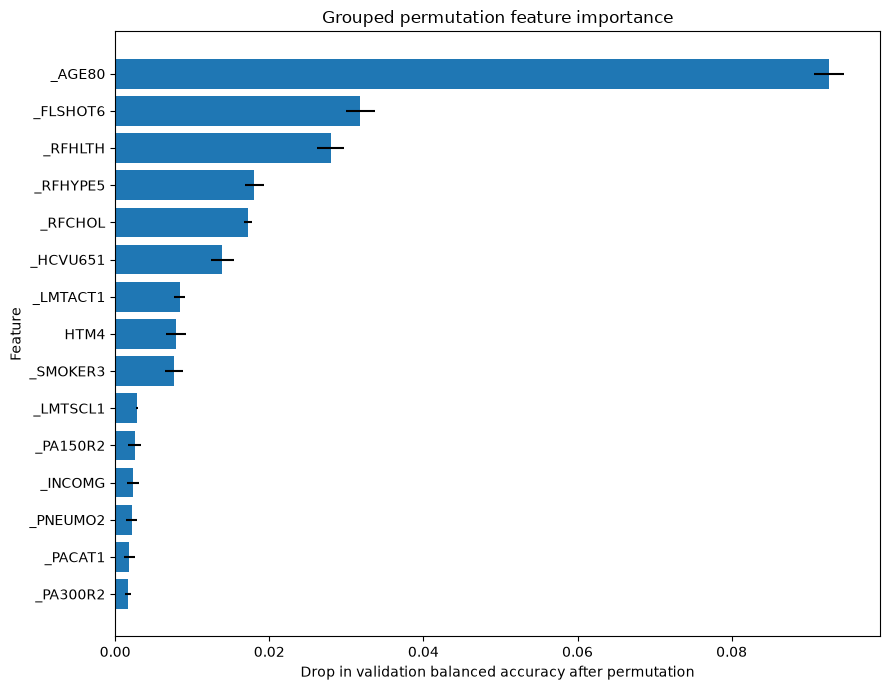

In [23]:
import matplotlib.pyplot as plt
top_n = 15
top_importance = permutation_importance[:top_n][::-1]

features = [row["feature"] for row in top_importance]
mean_drops = [row["mean_drop"] for row in top_importance]
std_drops = [row["std_drop"] for row in top_importance]

plt.figure(figsize=(9, 7))
plt.barh(
    features,
    mean_drops,
    xerr=std_drops,
)
plt.xlabel("Drop in validation balanced accuracy after permutation")
plt.ylabel("Feature")
plt.title("Grouped permutation feature importance")
plt.tight_layout()
plt.show()


### Reading permutation importance

- A **large positive drop** means the model relied strongly on that feature.
- A value near **0** means shuffling that feature alone barely changed validation performance.
- A **negative** value can occur from sampling noise or because shuffling happened to improve predictions slightly.
- Correlated features can share or mask one another's importance, so permutation importance should not be interpreted as a causal ranking.

This section intentionally recomputes importance from the current preprocessing/model pipeline rather than reusing results from an older notebook.


## Regularized Logistic Regression Experimentation

In [24]:
def select_feature_subset(
    x_train,
    x_val,
    headers,
    remove_features=None,
    keep_features=None,
):
    """
    Select encoded columns using original feature names.

    Use either remove_features or keep_features, not both.
    The intercept is always kept.
    """
    if remove_features is not None and keep_features is not None:
        raise ValueError(
            "Specify either remove_features or keep_features, not both."
        )

    headers = np.asarray(headers)

    def belongs_to_feature(header, feature):
        return (
            header == feature
            or header.startswith(feature + "_")
        )

    # Start by keeping everything
    mask = np.ones(len(headers), dtype=bool)

    if remove_features is not None:
        for feature in remove_features:
            feature_mask = np.array([
                belongs_to_feature(header, feature)
                for header in headers
            ])
            mask &= ~feature_mask

    elif keep_features is not None:
        mask = np.array([
            header == "intercept"
            or any(
                belongs_to_feature(header, feature)
                for feature in keep_features
            )
            for header in headers
        ])

    return (
        x_train[:, mask],
        x_val[:, mask],
        headers[mask],
    )

In [25]:
def run_reg_logistic_experiment(
    x_train,
    x_val,
    y_train,
    y_val,
    lambdas=REG_LOGISTIC_LAMBDAS,
    gamma=LOGISTIC_GAMMA,
    max_iters=LOGISTIC_MAX_ITERS,
    thresholds=LOGISTIC_THRESHOLDS,
):
    results = []

    for lambda_ in lambdas:
        initial_w = np.zeros(
            x_train.shape[1]
        )

        w, loss = reg_logistic_regression(
            y_train,
            x_train,
            lambda_,
            initial_w,
            max_iters,
            gamma,
        )

        if (
            not np.isfinite(loss)
            or not np.all(np.isfinite(w))
        ):
            continue

        val_prob = sigmoid(
            x_val @ w
        )

        evaluation = evaluate_thresholds(
            y_val,
            val_prob,
            thresholds,
        )

        results.append({
            "lambda": lambda_,
            "loss": loss,
            **evaluation,
        })

    best_balanced = max(
        results,
        key=lambda r:
            r["best_balanced_accuracy"],
    )

    return results, best_balanced

## Remove _AGE80

In [26]:
x_train_subset, x_val_subset, subset_headers = (
    select_feature_subset(
        x_train_final,
        x_val_final,
        headers_final,
        remove_features=["_AGE80"],
    )
)

results, best = run_reg_logistic_experiment(
    x_train_subset,
    x_val_subset,
    y_train_log,
    y_val_log,
)

print(best)

{'lambda': 0.0, 'loss': np.float64(0.23851709431264817), 'best_f1': np.float64(0.37990447977752245), 'f1_threshold': np.float64(0.16999999999999996), 'best_balanced_accuracy': np.float64(0.7561174942412814), 'balanced_threshold': np.float64(0.07999999999999999)}


## Remove _FLSHOT6

In [27]:
x_train_subset, x_val_subset, subset_headers = (
    select_feature_subset(
        x_train_final,
        x_val_final,
        headers_final,
        remove_features=["_FLSHOT6"],
    )
)

results, best = run_reg_logistic_experiment(
    x_train_subset,
    x_val_subset,
    y_train_log,
    y_val_log,
)

print(best)

{'lambda': 0.0, 'loss': np.float64(0.23517950289658918), 'best_f1': np.float64(0.39276518244049485), 'f1_threshold': np.float64(0.17999999999999997), 'best_balanced_accuracy': np.float64(0.761675659923714), 'balanced_threshold': np.float64(0.09)}


## Remove _AGE80, _FLSHOT6, and _PNEUMO2

In [28]:
x_train_subset, x_val_subset, subset_headers = (
    select_feature_subset(
        x_train_final,
        x_val_final,
        headers_final,
        remove_features=[
            "_AGE80",
            "_FLSHOT6",
            "_PNEUMO2",
        ],
    )
)
results, best = run_reg_logistic_experiment(
    x_train_subset,
    x_val_subset,
    y_train_log,
    y_val_log,
)

print(best)

{'lambda': 0.0, 'loss': np.float64(0.23892796218641393), 'best_f1': np.float64(0.37706898634771047), 'f1_threshold': np.float64(0.16999999999999996), 'best_balanced_accuracy': np.float64(0.7538478216429068), 'balanced_threshold': np.float64(0.07999999999999999)}


## Remove _FLSHOT6 and _PNEUMO2

In [29]:
x_train_subset, x_val_subset, subset_headers = (
    select_feature_subset(
        x_train_final,
        x_val_final,
        headers_final,
        remove_features=[
            "_FLSHOT6",
            "_PNEUMO2",
        ],
    )
)
results, best = run_reg_logistic_experiment(
    x_train_subset,
    x_val_subset,
    y_train_log,
    y_val_log,
)

print(best)

{'lambda': 0.0001, 'loss': np.float64(0.23543203523086714), 'best_f1': np.float64(0.38894184938036225), 'f1_threshold': np.float64(0.16999999999999996), 'best_balanced_accuracy': np.float64(0.7607860580231494), 'balanced_threshold': np.float64(0.09)}


## Interpretation
Permutation importance indicates which variables the fitted model relies on most strongly, with _AGE80 showing by far the largest importance. However, ablation experiments show that much of this information is shared with other predictors. Removing _AGE80 and retraining reduces balanced accuracy only moderately, from 0.7624 to 0.7561, while removing _FLSHOT6 has almost no effect despite its high permutation importance. This suggests substantial redundancy or correlation in the predictive information carried by the features.

## Top-k Feature Selection Experiment

In [30]:
# Rank original features by permutation importance
feature_ranking = [
    row["feature"]
    for row in permutation_importance
]

top_5 = feature_ranking[:5]
top_10 = feature_ranking[:10]
top_20 = feature_ranking[:20]

print("Top 5:", top_5)
print("Top 10:", top_10)
print("Top 20:", top_20)

Top 5: ['_AGE80', '_FLSHOT6', '_RFHLTH', '_RFHYPE5', '_RFCHOL']
Top 10: ['_AGE80', '_FLSHOT6', '_RFHLTH', '_RFHYPE5', '_RFCHOL', '_HCVU651', '_LMTACT1', 'HTM4', '_SMOKER3', '_LMTSCL1']
Top 20: ['_AGE80', '_FLSHOT6', '_RFHLTH', '_RFHYPE5', '_RFCHOL', '_HCVU651', '_LMTACT1', 'HTM4', '_SMOKER3', '_LMTSCL1', '_PA150R2', '_INCOMG', '_PNEUMO2', '_PACAT1', '_PA300R2', 'ACTIN11_', '_CHOLCHK', '_EDUCAG', '_ASTHMS1', '_RFBING5']


In [31]:
feature_set_experiments = {
    "Top 5": top_5,
    "Top 10": top_10,
    "Top 20": top_20,
    "All features": None,
}

In [34]:
top_k_results = []

for name, features_to_keep in feature_set_experiments.items():

    if features_to_keep is None:
        # Full baseline
        x_train_subset = x_train_final
        x_val_subset = x_val_final

    else:
        (
            x_train_subset,
            x_val_subset,
            subset_headers,
        ) = select_feature_subset(
            x_train_final,
            x_val_final,
            headers_final,
            keep_features=features_to_keep,
        )

    _, best = run_reg_logistic_experiment(
        x_train_subset,
        x_val_subset,
        y_train_log,
        y_val_log,
    )

    top_k_results.append({
        "feature_set": name,
        "n_original_features": (
            len(features_to_keep)
            if features_to_keep is not None
            else len(CALCULATED_FEATURES)
        ),
        "n_encoded_columns": x_train_subset.shape[1],
        **best,
    })

In [35]:
for result in top_k_results:
    print(
        f"{result['feature_set']:<15} | "
        f"features={result['n_original_features']:<2} | "
        f"columns={result['n_encoded_columns']:<3} | "
        f"lambda={result['lambda']:<7g} | "
        f"F1={result['best_f1']:.4f} "
        f"(t={result['f1_threshold']:.4f}) | "
        f"balanced acc={result['best_balanced_accuracy']:.4f} "
        f"(t={result['balanced_threshold']:.4f})"
    )

Top 5           | features=5  | columns=11  | lambda=1e-05   | F1=0.3691 (t=0.1700) | balanced acc=0.7499 (t=0.0900)
Top 10          | features=10 | columns=24  | lambda=0.0001  | F1=0.3848 (t=0.1700) | balanced acc=0.7573 (t=0.0800)
Top 20          | features=20 | columns=40  | lambda=0       | F1=0.3909 (t=0.1700) | balanced acc=0.7617 (t=0.0800)
All features    | features=49 | columns=78  | lambda=0.0001  | F1=0.3910 (t=0.1800) | balanced acc=0.7624 (t=0.0900)


### Interpretation

The top-k feature selection experiment shows that most of the predictive performance is concentrated in a relatively small subset of the available features.

Using only the top 5 features leads to a noticeable decrease in performance, with balanced accuracy dropping to approximately **0.750**. Expanding to the top 10 features recovers much of the lost performance, reaching approximately **0.757** balanced accuracy.

With the top 20 features, performance becomes almost identical to the full 49-feature model: balanced accuracy reaches **0.7617** compared with **0.7624** for the full model, while the F1 scores are virtually identical.

This suggests that the remaining 29 features provide only marginal additional predictive value for the current regularized logistic regression model. A substantially smaller feature set can therefore retain nearly all of the validation performance.